In [22]:
# ── 0. Imports ────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import warnings
warnings.filterwarnings("ignore")
 
torch.manual_seed(42)
np.random.seed(42)

In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# 1. DUMMY DATA GENERATION
# ══════════════════════════════════════════════════════════════════════════════
 
# ── 1a. Species list & trait matrix ──────────────────────────────────────────
#
# Each species has 4 ecological traits (all normalised to ~N(0,1)):
#   [temp_tolerance, precip_preference, dispersal_ability, habitat_generalism]
#
SPECIES = [
    "Vespa velutina",        # Asian hornet
    "Reynoutria japonica",   # Japanese knotweed
    "Ludwigia grandiflora",  # Water primrose
    "Harmonia axyridis",     # Harlequin ladybird
    "Procambarus clarkii",   # Red swamp crayfish
    "Ailanthus altissima",   # Tree of heaven
    "Myocastor coypus",      # Coypu
    "Impatiens glandulifera",# Himalayan balsam
]
N_SPECIES    = len(SPECIES)
TRAIT_DIM    = 4
SPECIES2IDX  = {sp: i for i, sp in enumerate(SPECIES)}
 
# Fake but plausible trait vectors per species
TRAIT_MATRIX = np.array([
    [ 0.8,  0.2,  1.2,  0.5],   # Vespa velutina
    [-0.3,  0.9,  0.4,  1.1],   # Reynoutria japonica
    [ 0.2,  1.5,  0.7,  0.3],   # Ludwigia grandiflora
    [ 0.6, -0.1,  1.4,  1.3],   # Harmonia axyridis
    [ 0.1,  1.2,  0.5,  0.8],   # Procambarus clarkii
    [ 1.1, -0.5,  0.9,  1.5],   # Ailanthus altissima
    [ 0.3,  1.0,  0.6,  0.4],   # Myocastor coypus
    [-0.2,  0.8,  1.1,  0.9],   # Impatiens glandulifera
], dtype=np.float32)             # shape: (8, 4)
 
 
# ── 1b. Fake GIS raster stacks ────────────────────────────────────────────────
#
# 4 bands: [Elevation, NDVI, Distance_to_Water, Land_Cover]
# Two country rasters (training / inference use) + a global training raster
#
GIS_BANDS    = ["Elevation", "NDVI", "Dist_Water", "Land_Cover"]
N_BANDS      = len(GIS_BANDS)
RASTER_H     = 64   # height in pixels
RASTER_W     = 64   # width  in pixels
 
def make_fake_raster(h=RASTER_H, w=RASTER_W, seed=0):
    """Generate a spatially coherent fake GIS raster (bands, H, W)."""
    rng = np.random.default_rng(seed)
    bands = []
    for _ in range(N_BANDS):
        # Smooth spatial structure via a coarse grid upsampled
        coarse = rng.standard_normal((h // 8, w // 8)).astype(np.float32)
        from numpy import kron
        smooth = kron(coarse, np.ones((8, 8), dtype=np.float32))[:h, :w]
        bands.append(smooth)
    return np.stack(bands)   # (4, H, W)
 
global_raster  = make_fake_raster(seed=1)   # training data
belgium_raster = make_fake_raster(seed=2)   # inference target
netherlands_raster = make_fake_raster(seed=3)
 
 
# ── 1c. Fake invasion occurrence records ─────────────────────────────────────
#
# For each species we generate positive pixel locations (invaded) drawn from
# regions of the global raster that match the species' preferred conditions.
# Negative records are sampled from everywhere else.
#
def generate_invasion_records(n_positive_per_species=40):
    records = []
    h, w = RASTER_H, RASTER_W
    pad  = 8   # half patch size — keep points away from border
 
    for sp_name, sp_idx in SPECIES2IDX.items():
        traits = TRAIT_MATRIX[sp_idx]
 
        # Positive pixels: weight sampling by similarity to species traits
        # (dot product of normalised raster pixel vector with trait vector)
        flat_pixels = global_raster.reshape(N_BANDS, -1).T   # (H*W, 4)
        similarity  = flat_pixels @ traits                    # (H*W,)
        similarity -= similarity.min()
        similarity /= (similarity.max() + 1e-8)
 
        # Flatten index → 2D, but only use pixels not near the border
        valid_mask = np.zeros(h * w, dtype=bool)
        for row in range(pad, h - pad):
            for col in range(pad, w - pad):
                valid_mask[row * w + col] = True
 
        probs = similarity * valid_mask
        probs /= probs.sum()
 
        pos_flat = np.random.choice(h * w, size=n_positive_per_species,
                                    replace=False, p=probs)
        for flat_idx in pos_flat:
            row = flat_idx // w
            col = flat_idx % w
            records.append({"species": sp_name, "species_idx": sp_idx,
                             "row": row, "col": col, "label": 1})
 
        # Negative pixels: random valid locations
        neg_flat = np.random.choice(
            np.where(valid_mask)[0],
            size=n_positive_per_species * 3,
            replace=False
        )
        for flat_idx in neg_flat:
            row = flat_idx // w
            col = flat_idx % w
            records.append({"species": sp_name, "species_idx": sp_idx,
                             "row": row, "col": col, "label": 0})
 
    return pd.DataFrame(records)
 
records_df = generate_invasion_records()
print(f"Training records: {len(records_df)} "
      f"({records_df.label.sum()} positive, "
      f"{(records_df.label==0).sum()} negative)")
print(records_df.head(8).to_string(index=False))

Training records: 1280 (320 positive, 960 negative)
       species  species_idx  row  col  label
Vespa velutina            0   26   46      1
Vespa velutina            0   53   46      1
Vespa velutina            0   43   20      1
Vespa velutina            0   36   53      1
Vespa velutina            0   16   10      1
Vespa velutina            0   10   55      1
Vespa velutina            0   50   19      1
Vespa velutina            0   37    9      1


In [24]:
# ══════════════════════════════════════════════════════════════════════════════
# 2. DATASET
# ══════════════════════════════════════════════════════════════════════════════
 
PATCH_SIZE = 16   # pixels × pixels neighbourhood around each occurrence point
 
class SpeciesPixelDataset(Dataset):
    def __init__(self, records: pd.DataFrame, gis: np.ndarray,
                 trait_matrix: np.ndarray, patch_size: int = PATCH_SIZE):
        self.gis         = gis
        self.trait_matrix = trait_matrix
        self.patch_size  = patch_size
        self.samples     = []          # (patch, sp_idx, label)
 
        h = patch_size // 2
        for _, row in records.iterrows():
            cy, cx = int(row.row), int(row.col)
            # Guard against border pixels
            if cy - h < 0 or cy + h > gis.shape[1]: continue
            if cx - h < 0 or cx + h > gis.shape[2]: continue
            patch = gis[:, cy-h:cy+h, cx-h:cx+h].astype(np.float32)
            self.samples.append((patch, int(row.species_idx), float(row.label)))
 
    def __len__(self):
        return len(self.samples)
 
    def __getitem__(self, i):
        patch, sp_idx, label = self.samples[i]
        traits = self.trait_matrix[sp_idx]
        return (
            torch.tensor(patch),
            torch.tensor(sp_idx, dtype=torch.long),
            torch.tensor(traits, dtype=torch.float32),
            torch.tensor(label,  dtype=torch.float32),
        )
 
 
# ── Train / test split by species (not by record!) ───────────────────────────
test_species  = SPECIES[-2:]   # hold out last 2 species entirely
train_species = SPECIES[:-2]
 
print(f"\nTrain species ({len(train_species)}): {train_species}")
print(f"Test  species ({len(test_species)}):  {test_species}")
 
train_records = records_df[~records_df.species.isin(test_species)]
test_records  = records_df[ records_df.species.isin(test_species)]
 
train_ds = SpeciesPixelDataset(train_records, global_raster, TRAIT_MATRIX)
test_ds  = SpeciesPixelDataset(test_records,  global_raster, TRAIT_MATRIX)
 
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)
 
print(f"\nDataset sizes — train: {len(train_ds)}, test: {len(test_ds)}")
 


Train species (6): ['Vespa velutina', 'Reynoutria japonica', 'Ludwigia grandiflora', 'Harmonia axyridis', 'Procambarus clarkii', 'Ailanthus altissima']
Test  species (2):  ['Myocastor coypus', 'Impatiens glandulifera']

Dataset sizes — train: 960, test: 320


In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# 3. MODEL
# ══════════════════════════════════════════════════════════════════════════════
 
class SharedInvasionModel(nn.Module):
    def __init__(self, in_channels, patch_size, n_species,
                 species_feat_dim, embed_dim=16):
        super().__init__()
 
        # GIS patch encoder
        self.pixel_encoder = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64,       kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten()
        )
 
        # Species encoder: explicit ecological traits
        self.trait_encoder = nn.Sequential(
            nn.Linear(species_feat_dim, 32), nn.ReLU(),
            nn.Linear(32, embed_dim)
        )
 
        # Learned species embedding (captures variance beyond traits)
        self.species_emb = nn.Embedding(n_species, embed_dim)
 
        # Dynamically compute fusion size
        with torch.no_grad():
            dummy = torch.zeros(1, in_channels, patch_size, patch_size)
            pixel_dim = self.pixel_encoder(dummy).shape[1]
 
        fusion_dim = pixel_dim + embed_dim + embed_dim
 
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 32),         nn.ReLU(),
            nn.Linear(32, 1)
            # No sigmoid — use BCEWithLogitsLoss
        )
 
    def forward(self, patch, species_idx, species_traits):
        pixel_feat = self.pixel_encoder(patch)
        trait_feat = self.trait_encoder(species_traits)
        emb_feat   = self.species_emb(species_idx)
        combined   = torch.cat([pixel_feat, trait_feat, emb_feat], dim=1)
        return self.classifier(combined)
 
 
model = SharedInvasionModel(
    in_channels      = N_BANDS,
    patch_size       = PATCH_SIZE,
    n_species        = N_SPECIES,
    species_feat_dim = TRAIT_DIM,
    embed_dim        = 16
)
print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
 


Model parameters: 159,953


Epoch 01/100  train_loss=0.9852  test_loss=1.0817
Epoch 05/100  train_loss=0.9329  test_loss=1.1473
Epoch 10/100  train_loss=0.8797  test_loss=1.1945
Epoch 15/100  train_loss=0.8471  test_loss=1.2544
Epoch 20/100  train_loss=0.8113  test_loss=1.2897
Epoch 25/100  train_loss=0.8020  test_loss=1.2945
Epoch 30/100  train_loss=0.8137  test_loss=1.3048
Epoch 35/100  train_loss=0.7883  test_loss=1.3114
Epoch 40/100  train_loss=0.7950  test_loss=1.3131
Epoch 45/100  train_loss=0.7854  test_loss=1.3146
Epoch 50/100  train_loss=0.7874  test_loss=1.3149
Epoch 55/100  train_loss=0.7935  test_loss=1.3152
Epoch 60/100  train_loss=0.7765  test_loss=1.3154
Epoch 65/100  train_loss=0.7924  test_loss=1.3155
Epoch 70/100  train_loss=0.7821  test_loss=1.3155
Epoch 75/100  train_loss=0.8033  test_loss=1.3155
Epoch 80/100  train_loss=0.7869  test_loss=1.3155
Epoch 85/100  train_loss=0.7850  test_loss=1.3155
Epoch 90/100  train_loss=0.7840  test_loss=1.3155
Epoch 95/100  train_loss=0.7967  test_loss=1.3155


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/training_curve.png'

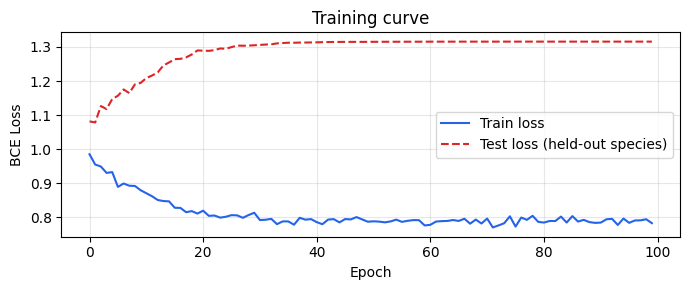

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# 4. TRAINING
# ══════════════════════════════════════════════════════════════════════════════
 
N_EPOCHS  = 100
LR        = 1e-3
# pos_weight accounts for 3:1 negative:positive ratio
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([3.0]))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
 
train_losses, test_losses = [], []
 
for epoch in range(1, N_EPOCHS + 1):
    # ── train ──
    model.train()
    epoch_loss = 0.0
    for patch, sp_idx, traits, label in train_loader:
        optimizer.zero_grad()
        logits = model(patch, sp_idx, traits).squeeze(1)
        loss   = criterion(logits, label)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(label)
    train_losses.append(epoch_loss / len(train_ds))
 
    # ── eval ──
    model.eval()
    eval_loss = 0.0
    with torch.no_grad():
        for patch, sp_idx, traits, label in test_loader:
            logits = model(patch, sp_idx, traits).squeeze(1)
            eval_loss += criterion(logits, label).item() * len(label)
    test_losses.append(eval_loss / len(test_ds))
    scheduler.step()
 
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{N_EPOCHS}  "
              f"train_loss={train_losses[-1]:.4f}  "
              f"test_loss={test_losses[-1]:.4f}")
 
 
# ── Plot training curve ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(train_losses, label="Train loss", color="#2563eb")
ax.plot(test_losses,  label="Test loss (held-out species)", color="#dc2626",
        linestyle="--")
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss")
ax.set_title("Training curve"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig("/mnt/user-data/outputs/training_curve.png", dpi=150) #ADAP if needed
plt.show()
print("Saved training_curve.png")

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# 5. INFERENCE — rank all species for a target country
# ══════════════════════════════════════════════════════════════════════════════
 
def rank_species_for_country(model, candidate_species, country_gis,
                              trait_matrix, patch_size=PATCH_SIZE, stride=8):
    """
    For each candidate species, slide a window over the country raster
    and compute pixel-level invasion probability.
 
    Returns:
        results_df  — ranked DataFrame with risk scores
        risk_maps   — dict of {species_name: (H, W) probability array}
    """
    C, H, W = country_gis.shape
    h       = patch_size // 2
    model.eval()
 
    # ── Pre-extract all patches once (reused for every species) ──
    patches, rows_cols = [], []
    for cy in range(h, H - h, stride):
        for cx in range(h, W - h, stride):
            patch = country_gis[:, cy-h:cy+h, cx-h:cx+h]
            patches.append(patch)
            rows_cols.append((cy, cx))
 
    patch_tensor = torch.tensor(
        np.stack(patches).astype(np.float32)
    )   # (N_patches, C, pH, pW)
    N_patches = len(patches)
 
    results  = []
    risk_maps = {}
 
    for sp_name, sp_idx in candidate_species:
        traits       = torch.tensor(trait_matrix[sp_idx], dtype=torch.float32)
        traits_batch = traits.unsqueeze(0).expand(N_patches, -1)
        sp_batch     = torch.full((N_patches,), sp_idx, dtype=torch.long)
 
        with torch.no_grad():
            logits = model(patch_tensor, sp_batch, traits_batch).squeeze(1)
            probs  = torch.sigmoid(logits).numpy()
 
        # Reconstruct spatial risk map (average overlapping patches)
        risk_map  = np.zeros((H, W), dtype=np.float32)
        count_map = np.zeros((H, W), dtype=np.float32)
        for prob, (cy, cx) in zip(probs, rows_cols):
            risk_map [cy-h:cy+h, cx-h:cx+h] += prob
            count_map[cy-h:cy+h, cx-h:cx+h] += 1
        count_map[count_map == 0] = 1
        risk_map /= count_map
 
        # Aggregate to single species score (mean of top 10% pixels)
        threshold = np.percentile(probs, 90)
        score     = float(probs[probs >= threshold].mean())
 
        results.append({
            "species":    sp_name,
            "risk_score": score,
            "mean_risk":  float(probs.mean()),
            "max_risk":   float(probs.max()),
        })
        risk_maps[sp_name] = risk_map
 
    results_df = (pd.DataFrame(results)
                    .sort_values("risk_score", ascending=False)
                    .reset_index(drop=True))
    return results_df, risk_maps
 
 
# ── Run for Belgium (all species treated as candidates) ───────────────────────
candidate_species = list(SPECIES2IDX.items())   # all 8 species
 
be_results, be_risk_maps = rank_species_for_country(
    model, candidate_species, belgium_raster, TRAIT_MATRIX
)
 
print("\n=== BELGIUM — Species Invasion Risk Ranking ===")
print(be_results.to_string(index=False))
 


=== BELGIUM — Species Invasion Risk Ranking ===
               species  risk_score  mean_risk  max_risk
     Harmonia axyridis    0.809159   0.493869  0.862376
      Myocastor coypus    0.804043   0.483584  0.869057
  Ludwigia grandiflora    0.801909   0.494119  0.879306
        Vespa velutina    0.801052   0.485470  0.873616
   Reynoutria japonica    0.797113   0.484007  0.902428
   Procambarus clarkii    0.790512   0.483786  0.854987
Impatiens glandulifera    0.789517   0.477321  0.857579
   Ailanthus altissima    0.775783   0.438392  0.859956


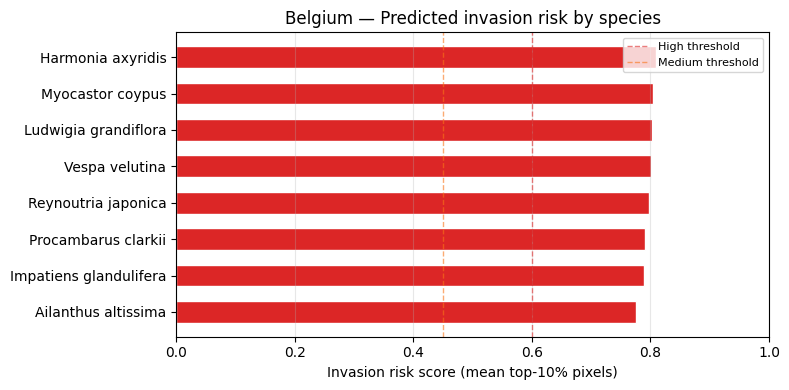

Saved risk_ranking_belgium.png


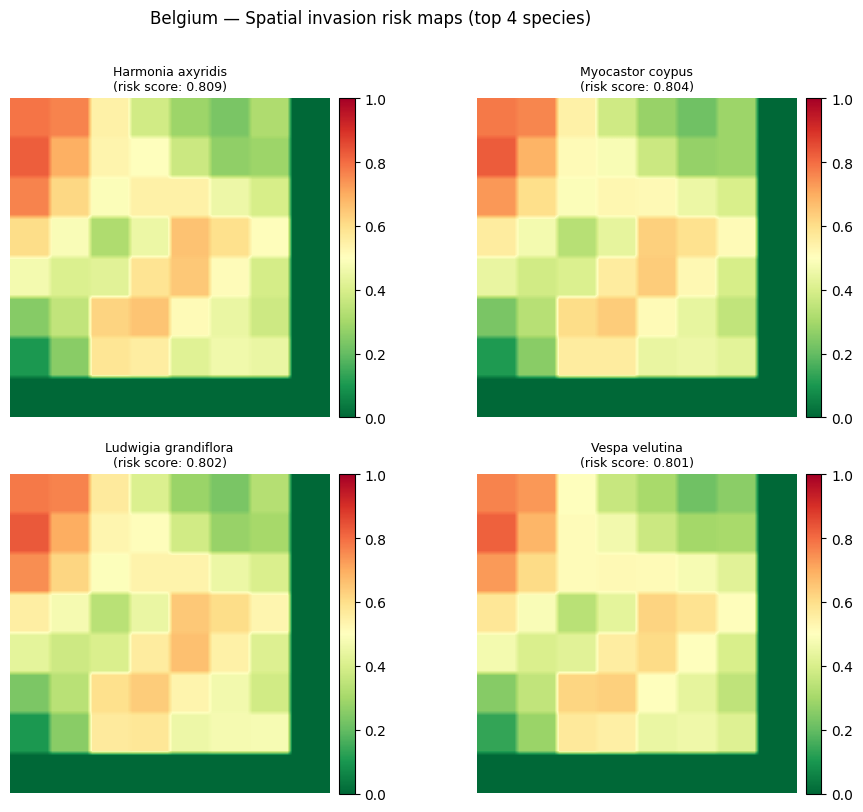

Saved risk_maps_belgium.png

=== Multi-country comparison ===
               species  Belgium  Netherlands
     Harmonia axyridis 0.809159     0.911510
      Myocastor coypus 0.804043     0.898505
  Ludwigia grandiflora 0.801909     0.908461
        Vespa velutina 0.801052     0.888612
   Reynoutria japonica 0.797113     0.901584
   Procambarus clarkii 0.790512     0.905961
Impatiens glandulifera 0.789517     0.905534
   Ailanthus altissima 0.775783     0.862533


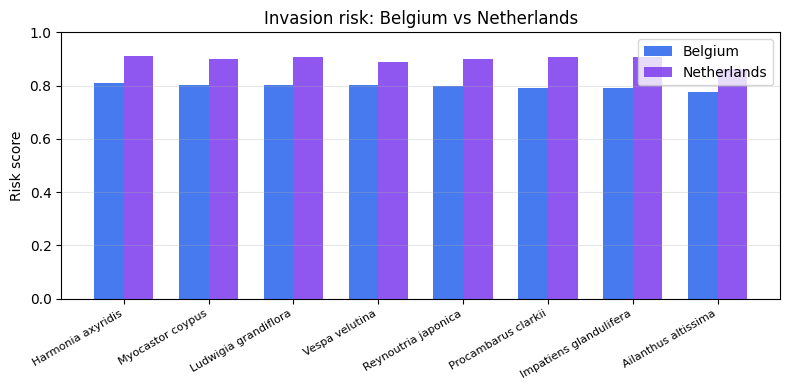

Saved country_comparison.png

✓ All done.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# 6. VISUALISATION
# ══════════════════════════════════════════════════════════════════════════════
 
# ── 6a. Bar chart: ranked risk scores ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
colors  = ["#dc2626" if s > 0.6 else "#f97316" if s > 0.45 else "#16a34a"
           for s in be_results.risk_score]
bars = ax.barh(be_results.species[::-1], be_results.risk_score[::-1],
               color=colors[::-1], edgecolor="white", height=0.6)
ax.axvline(0.6, color="#dc2626", linestyle="--", lw=1, alpha=0.6, label="High threshold")
ax.axvline(0.45, color="#f97316", linestyle="--", lw=1, alpha=0.6, label="Medium threshold")
ax.set_xlabel("Invasion risk score (mean top-10% pixels)")
ax.set_title("Belgium — Predicted invasion risk by species")
ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
#plt.savefig("/mnt/user-data/outputs/risk_ranking_belgium.png", dpi=150)
plt.show()
print("Saved risk_ranking_belgium.png")
 
 
# ── 6b. Spatial risk maps for top 4 species ──────────────────────────────────
top4 = be_results.species.iloc[:4].tolist()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
 
for ax, sp_name in zip(axes.flat, top4):
    rmap  = be_risk_maps[sp_name]
    score = be_results.loc[be_results.species == sp_name, "risk_score"].values[0]
    im    = ax.imshow(rmap, cmap="RdYlGn_r", vmin=0, vmax=1,
                      interpolation="bilinear")
    ax.set_title(f"{sp_name}\n(risk score: {score:.3f})", fontsize=9)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
 
fig.suptitle("Belgium — Spatial invasion risk maps (top 4 species)", y=1.01)
plt.tight_layout()
#plt.savefig("/mnt/user-data/outputs/risk_maps_belgium.png", dpi=150,
#            bbox_inches="tight")
plt.show()
print("Saved risk_maps_belgium.png")
 
 
# ── 6c. Multi-country comparison (Belgium vs Netherlands) ─────────────────────
nl_results, _ = rank_species_for_country(
    model, candidate_species, netherlands_raster, TRAIT_MATRIX
)
 
comparison = (be_results[["species","risk_score"]]
              .rename(columns={"risk_score": "Belgium"})
              .merge(nl_results[["species","risk_score"]]
                     .rename(columns={"risk_score": "Netherlands"}),
                     on="species")
              .sort_values("Belgium", ascending=False))
 
print("\n=== Multi-country comparison ===")
print(comparison.to_string(index=False))
 
fig, ax = plt.subplots(figsize=(8, 4))
x       = np.arange(len(comparison))
width   = 0.35
ax.bar(x - width/2, comparison.Belgium,     width, label="Belgium",
       color="#2563eb", alpha=0.85)
ax.bar(x + width/2, comparison.Netherlands, width, label="Netherlands",
       color="#7c3aed", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(comparison.species, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Risk score"); ax.set_ylim(0, 1)
ax.set_title("Invasion risk: Belgium vs Netherlands")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
#plt.savefig("/mnt/user-data/outputs/country_comparison.png", dpi=150)
plt.show()
 